# 09 — Spatial Validation

## Objective

This notebook evaluates the spatial characteristics of the 30 m LST downscaled products using additional spatial validation measures.

The analysis is designed to determine whether Random Forest and XGBoost preserve meaningful spatial structure in the downscaled LST products rather than simply producing smoother temperature distributions.

### Analyses

1. Moran's I — spatial autocorrelation
2. Variogram analysis — spatial dependence across distance
3. Hotspot preservation — spatial agreement of thermal extremes
4. Thermal variability and smoothing assessment

## 1. Moran's I — Spatial Autocorrelation

In [10]:
!pip install libpysal esda


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import numpy as np
from pathlib import Path
import rasterio
from libpysal.weights import lat2W
from esda.moran import Moran

In [12]:
PROJECT_DIR = Path(r"D:\Projects\GeoAI-LST-Downscaling")
FINE_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "fine"
COARSE_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "coarse"
DOWNSCALED_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "downscaled"

reference_path = FINE_DIR/ "predictors" / "lst_clean_lucknow.tif"
tsharp_path = DOWNSCALED_DIR / "tsharp_lst_30m_lucknow.tif"
rf_path = DOWNSCALED_DIR / "rf_lst_30m_lucknow.tif"
xgb_path = DOWNSCALED_DIR / "xgb_lst_30m_lucknow.tif"

In [13]:




def read_raster(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Raster not found: {path}")

    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float64)
        profile = src.profile.copy()
        nodata = src.nodata

    # Convert NoData values to NaN
    if nodata is not None and not np.isnan(nodata):
        data[data == nodata] = np.nan

    return data, profile, nodata

reference, ref_profile, ref_nodata = read_raster(reference_path)
tsharp, tsharp_profile, tsharp_nodata = read_raster(tsharp_path)
rf, rf_profile, rf_nodata = read_raster(rf_path)
xgb, xgb_profile, xgb_nodata = read_raster(xgb_path)

print("Reference:", reference.shape)
print("TsHARP:", tsharp.shape)
print("RF:", rf.shape)
print("XGBoost:", xgb.shape)

Reference: (703, 762)
TsHARP: (702, 762)
RF: (703, 762)
XGBoost: (703, 762)


In [14]:
print("Reference shape:", reference.shape)
print("TsHARP shape:", tsharp.shape)
print("RF shape:", rf.shape)
print("XGBoost shape:", xgb.shape)

print("Reference resolution:", ref_profile["transform"].a, abs(ref_profile["transform"].e))
print("TsHARP resolution:", tsharp_profile["transform"].a, abs(tsharp_profile["transform"].e))
print("RF resolution:", rf_profile["transform"].a, abs(rf_profile["transform"].e))
print("XGBoost resolution:", xgb_profile["transform"].a, abs(xgb_profile["transform"].e))



Reference shape: (703, 762)
TsHARP shape: (702, 762)
RF shape: (703, 762)
XGBoost shape: (703, 762)
Reference resolution: 30.0 30.0
TsHARP resolution: 30.0 30.0
RF resolution: 30.0 30.0
XGBoost resolution: 30.0 30.0


In [15]:
rasters = {
    "Reference": (reference, ref_profile),
    "TsHARP": (tsharp, tsharp_profile),
    "Random Forest": (rf, rf_profile),
    "XGBoost": (xgb, xgb_profile),
}

for name, (data, profile) in rasters.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Transform:", profile["transform"])
    print("Bounds:", rasterio.transform.array_bounds(
        data.shape[0],
        data.shape[1],
        profile["transform"]
    ))


Reference
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)

TsHARP
Shape: (702, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958105.0, 506085.0, 2979165.0)

Random Forest
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)

XGBoost
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)


In [16]:
print("\nCRS:")
for name, (_, profile) in rasters.items():
    print(name, profile["crs"])

print("\nResolution:")
for name, (_, profile) in rasters.items():
    print(
        name,
        profile["transform"].a,
        abs(profile["transform"].e)
    )


CRS:
Reference EPSG:32644
TsHARP EPSG:32644
Random Forest EPSG:32644
XGBoost EPSG:32644

Resolution:
Reference 30.0 30.0
TsHARP 30.0 30.0
Random Forest 30.0 30.0
XGBoost 30.0 30.0


In [17]:
# Crop all rasters to the common spatial extent
common_rows = min(
    reference.shape[0],
    tsharp.shape[0],
    rf.shape[0],
    xgb.shape[0]
)

common_cols = min(
    reference.shape[1],
    tsharp.shape[1],
    rf.shape[1],
    xgb.shape[1]
)

reference_common = reference[:common_rows, :common_cols]
tsharp_common = tsharp[:common_rows, :common_cols]
rf_common = rf[:common_rows, :common_cols]
xgb_common = xgb[:common_rows, :common_cols]

print("Reference:", reference_common.shape)
print("TsHARP:", tsharp_common.shape)
print("RF:", rf_common.shape)
print("XGBoost:", xgb_common.shape)

Reference: (702, 762)
TsHARP: (702, 762)
RF: (702, 762)
XGBoost: (702, 762)


In [18]:
valid_mask = (
    np.isfinite(reference_common) &
    np.isfinite(tsharp_common) &
    np.isfinite(rf_common) &
    np.isfinite(xgb_common)
)

print("Total pixels:", valid_mask.size)
print("Valid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())

Total pixels: 534924
Valid pixels: 314648
Invalid pixels: 220276


In [19]:
reference_values = reference_common[valid_mask]
tsharp_values = tsharp_common[valid_mask]
rf_values = rf_common[valid_mask]
xgb_values = xgb_common[valid_mask]

print("Number of valid pixels:", len(reference_values))

Number of valid pixels: 314648


In [20]:
from libpysal.weights import lat2W

rows, cols = reference.shape

# Rook contiguity: edge-sharing neighbours
w = lat2W(rows, cols, rook=True)
# Create rook-contiguity weights for the complete raster grid
w_full = lat2W(rows, cols, rook=True)
print("Number of spatial units:", w.n)
print("Number of neighbours for first pixel:", len(w.neighbors[0]))

Number of spatial units: 535686
Number of neighbours for first pixel: 2


In [21]:
print("Total pixels:", reference.size)
print("Valid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())

Total pixels: 535686
Valid pixels: 314648
Invalid pixels: 220276


In [22]:
valid_flat = valid_mask.flatten()

valid_indices = np.where(valid_flat)[0]

print("Valid spatial units:", len(valid_indices))

Valid spatial units: 314648


In [23]:
from libpysal.weights import W

valid_indices = np.where(valid_flat)[0]

# Map original raster index -> new index
index_map = {
    old_idx: new_idx
    for new_idx, old_idx in enumerate(valid_indices)
}

neighbors = {}
weights = {}

for old_idx in valid_indices:
    new_idx = index_map[old_idx]

    # Original neighbours from the full raster
    old_neighbors = w_full.neighbors[old_idx]

    # Keep only neighbours that are also valid
    valid_neighbors = [
        n for n in old_neighbors
        if n in index_map
    ]

    neighbors[new_idx] = [
        index_map[n] for n in valid_neighbors
    ]

    weights[new_idx] = [1.0] * len(valid_neighbors)

# Create the reduced spatial weights object
w = W(neighbors, weights)

print("Original spatial units:", w_full.n)
print("Valid spatial units:", len(valid_indices))
print("Spatial units in new weights:", w.n)

Original spatial units: 535686
Valid spatial units: 314648
Spatial units in new weights: 314648


In [24]:
print("Number of islands:", w.n_components)
print("Average neighbours:", np.mean(list(map(len, w.neighbors.values()))))

Number of islands: 1
Average neighbours: 3.9876941852482775


In [25]:
reference_values = reference_common[valid_mask]
tsharp_values = tsharp_common[valid_mask]
rf_values = rf_common[valid_mask]
xgb_values = xgb_common[valid_mask]

In [26]:
from esda.moran import Moran

# Calculate Moran's I
moran_reference = Moran(
    reference_values,
    w,
    permutations=999
)

moran_tsharp = Moran(
    tsharp_values,
    w,
    permutations=999
)

moran_rf = Moran(
    rf_values,
    w,
    permutations=999
)

moran_xgb = Moran(
    xgb_values,
    w,
    permutations=999
)

In [27]:
print("Reference 30 m")
print("Moran's I:", moran_reference.I)
print("Expected I:", moran_reference.EI)
print("Z-score:", moran_reference.z_sim)
print("Permutation p-value:", moran_reference.p_sim)

print("\nTsHARP 30 m")
print("Moran's I:", moran_tsharp.I)
print("Expected I:", moran_tsharp.EI)
print("Z-score:", moran_tsharp.z_sim)
print("Permutation p-value:", moran_tsharp.p_sim)

print("\nRandom Forest 30 m")
print("Moran's I:", moran_rf.I)
print("Expected I:", moran_rf.EI)
print("Z-score:", moran_rf.z_sim)
print("Permutation p-value:", moran_rf.p_sim)

print("\nXGBoost 30 m")
print("Moran's I:", moran_xgb.I)
print("Expected I:", moran_xgb.EI)
print("Z-score:", moran_xgb.z_sim)
print("Permutation p-value:", moran_xgb.p_sim)

Reference 30 m
Moran's I: 0.9842988877260397
Expected I: -3.178164736990977e-06
Z-score: 804.8387742724453
Permutation p-value: 0.001

TsHARP 30 m
Moran's I: 0.9438660487743782
Expected I: -3.178164736990977e-06
Z-score: 750.1493210638631
Permutation p-value: 0.001

Random Forest 30 m
Moran's I: 0.8138341868665738
Expected I: -3.178164736990977e-06
Z-score: 655.1660330446883
Permutation p-value: 0.001

XGBoost 30 m
Moran's I: 0.828310805810523
Expected I: -3.178164736990977e-06
Z-score: 631.4831064835631
Permutation p-value: 0.001


In [28]:
import pandas as pd

RESULTS_DIR = PROJECT_DIR / "results" / "spatial_validation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

moran_results = {
    "Reference": {
        "Moran_I": moran_reference.I,
        "Expected_I": moran_reference.EI,
        "Z_score": moran_reference.z_sim,
        "p_value": moran_reference.p_sim,
    },
    "TsHARP": {
        "Moran_I": moran_tsharp.I,
        "Expected_I": moran_tsharp.EI,
        "Z_score": moran_tsharp.z_sim,
        "p_value": moran_tsharp.p_sim,
    },
    "Random Forest": {
        "Moran_I": moran_rf.I,
        "Expected_I": moran_rf.EI,
        "Z_score": moran_rf.z_sim,
        "p_value": moran_rf.p_sim,
    },
    "XGBoost": {
        "Moran_I": moran_xgb.I,
        "Expected_I": moran_xgb.EI,
        "Z_score": moran_xgb.z_sim,
        "p_value": moran_xgb.p_sim,
    },
}

moran_df = pd.DataFrame.from_dict(moran_results, orient="index")

moran_output = RESULTS_DIR / "moran_i_results.csv"
moran_df.to_csv(moran_output, index_label="Method")

print(f"Moran's I results saved to:\n{moran_output}")

moran_df

Moran's I results saved to:
D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\moran_i_results.csv


,Moran_I,Expected_I,Z_score,p_value
Reference,0.984299,-0.000003,804.838774,0.001
TsHARP,0.943866,-0.000003,750.149321,0.001
Random Forest,0.813834,-0.000003,655.166033,0.001
XGBoost,0.828311,-0.000003,631.483106,0.001


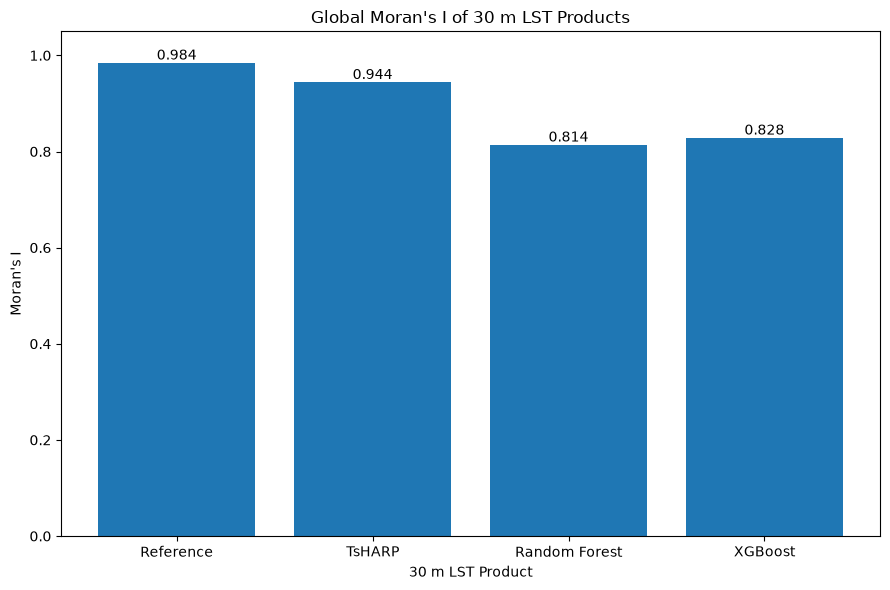

<Figure size 640x480 with 0 Axes>

In [44]:
import matplotlib.pyplot as plt
import numpy as np
FIGURES_DIR = PROJECT_DIR / "figures" / "lucknow" / "notebook_9"

models = [
    "Reference",
    "TsHARP",
    "Random Forest",
    "XGBoost"
]

moran_values = [
    moran_reference.I,
    moran_tsharp.I,
    moran_rf.I,
    moran_xgb.I
]

plt.figure(figsize=(9, 6))

bars = plt.bar(models, moran_values)

plt.ylabel("Moran's I")
plt.xlabel("30 m LST Product")
plt.title("Global Moran's I of 30 m LST Products")

# Add values above bars
for bar, value in zip(bars, moran_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()
plt.savefig(FIGURES_DIR/ "Moran's_I_30m_LST")

## 2. Variogram - Difference in Temperatures of Pixels as the distance increases

In [29]:
!pip install scikit-gstat


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from skgstat import Variogram

In [31]:
print("Reference:", reference_common.shape)
print("TsHARP:", tsharp_common.shape)
print("RF:", rf_common.shape)
print("XGBoost:", xgb_common.shape)

print("Common valid pixels:", valid_mask.sum())

Reference: (702, 762)
TsHARP: (702, 762)
RF: (702, 762)
XGBoost: (702, 762)
Common valid pixels: 314648


In [32]:
# Get coordinates of common valid pixels
valid_coords = np.column_stack(np.where(valid_mask))

print("Total common valid pixels:", len(valid_coords))

# Reproducible sample
rng = np.random.default_rng(42)

n_samples = min(5000, len(valid_coords))

sample_idx = rng.choice(
    len(valid_coords),
    size=n_samples,
    replace=False
)

sample_coords = valid_coords[sample_idx]

print("Sampled pixels:", len(sample_coords))

Total common valid pixels: 314648
Sampled pixels: 5000


In [33]:
ref_values = reference_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

tsharp_values = tsharp_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

rf_values = rf_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

xgb_values = xgb_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

In [34]:
sample_coords_m = sample_coords.astype(float) * 30

In [35]:
V_ref = Variogram(
    sample_coords_m,
    ref_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_tsharp = Variogram(
    sample_coords_m,
    tsharp_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_rf = Variogram(
    sample_coords_m,
    rf_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_xgb = Variogram(
    sample_coords_m,
    xgb_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

In [36]:
print("Reference:")
print("Effective range:", V_ref.parameters[0])
print("Sill:", V_ref.parameters[1])
print("Nugget:", V_ref.parameters[2])

print("\nTsHARP:")
print("Effective range:", V_tsharp.parameters[0])
print("Sill:", V_tsharp.parameters[1])
print("Nugget:", V_tsharp.parameters[2])

print("\nRandom Forest:")
print("Effective range:", V_rf.parameters[0])
print("Sill:", V_rf.parameters[1])
print("Nugget:", V_rf.parameters[2])

print("\nXGBoost:")
print("Effective range:", V_xgb.parameters[0])
print("Sill:", V_xgb.parameters[1])
print("Nugget:", V_xgb.parameters[2])

Reference:
Effective range: 1325.7110044877159
Sill: 1.5013468299089163
Nugget: 0

TsHARP:
Effective range: 1189.3927716187923
Sill: 1.576230121373448
Nugget: 0

Random Forest:
Effective range: 619.597707663426
Sill: 1.545354596277274
Nugget: 0

XGBoost:
Effective range: 643.6450081167225
Sill: 1.4816470682911704
Nugget: 0


In [47]:
variogram_results = {
    "Reference": V_ref,
    "TsHARP": V_tsharp,
    "Random Forest": V_rf,
    "XGBoost": V_xgb,
}

# Save fitted variogram parameters
variogram_summary = pd.DataFrame([
    {
        "Method": name,
        "Effective_range_m": variogram.parameters[0],
        "Sill": variogram.parameters[1],
        "Nugget": variogram.parameters[2],
    }
    for name, variogram in variogram_results.items()
])

variogram_summary_path = RESULTS_DIR / "variogram_results.csv"
variogram_summary.to_csv(variogram_summary_path, index=False)


print(f"Saved summary to: {variogram_summary_path}")

Saved summary to: D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\variogram_results.csv


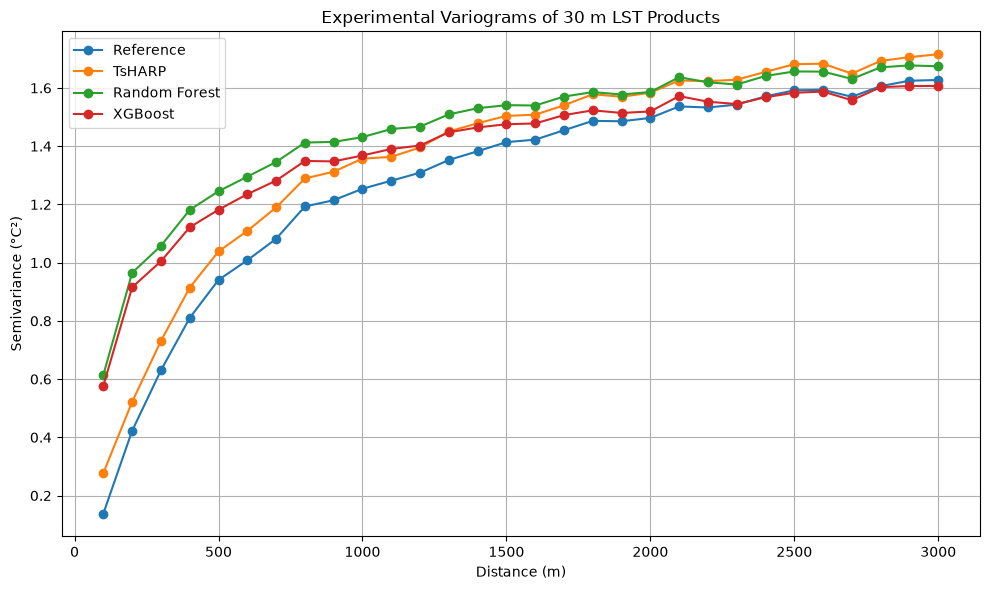

<Figure size 640x480 with 0 Axes>

In [45]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.plot(
    V_ref.bins,
    V_ref.experimental,
    marker='o',
    label='Reference'
)

plt.plot(
    V_tsharp.bins,
    V_tsharp.experimental,
    marker='o',
    label='TsHARP'
)

plt.plot(
    V_rf.bins,
    V_rf.experimental,
    marker='o',
    label='Random Forest'
)

plt.plot(
    V_xgb.bins,
    V_xgb.experimental,
    marker='o',
    label='XGBoost'
)

plt.xlabel("Distance (m)")
plt.ylabel("Semivariance (°C²)")
plt.title("Experimental Variograms of 30 m LST Products")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
plt.savefig(FIGURES_DIR/"Variogram_30m_LST")